In [1]:
!pip install -q huggingface_hub

In [2]:
from huggingface_hub import hf_hub_download
import zipfile
import shutil
from pathlib import Path, PurePosixPath

REPO_ID = "ParsaVictor/pcb-bare-board-defect-detection"

ZIP_DIR = Path("/content/pcb_zips")
OUTPUT_DIR = Path("/content/pcb_data")

ZIP_DIR.mkdir(exist_ok=True)

for split in ["train", "val", "test"]:

    filename = f"{split}_images_and_labels.zip"

    print(f"\nDownloading {split.upper()} dataset...")

    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=filename,
        local_dir=str(ZIP_DIR)
    )

    print(f"Download completed: {filename}")
    print(f"Extracting {split.upper()}...")

    images = 0
    labels = 0

    with zipfile.ZipFile(zip_path, "r") as zf:

        for member in zf.infolist():

            if member.is_dir():
                continue

            path = PurePosixPath(member.filename)
            parts = path.parts

            if len(parts) < 4:
                continue

            if parts[0] != "final_bare" or parts[2] != split:
                continue

            category = parts[1]
            ext = path.suffix.lower()

            if category == "images" and ext in [".jpg", ".jpeg", ".png"]:
                destination = OUTPUT_DIR / "images" / split
                images += 1

            elif category == "labels" and ext == ".txt":
                destination = OUTPUT_DIR / "labels" / split
                labels += 1

            else:
                continue

            destination.mkdir(parents=True, exist_ok=True)

            output_file = destination / path.name

            with zf.open(member) as src, open(output_file, "wb") as dst:
                shutil.copyfileobj(src, dst)

    print(f"Images extracted: {images}")
    print(f"Labels extracted: {labels}")

    # Remove downloaded ZIP after successful extraction
    Path(zip_path).unlink()

print("\nAll datasets downloaded and extracted!")
print("Dataset location:", OUTPUT_DIR)

train_images_and_labels.zip: reconstructing file:   0%|          |  0.00B / 3.88GB            

train_images_and_labels.zip: downloading bytes:           |  0.00B            

Download completed: train_images_and_labels.zip
Extracting TRAIN...
Images extracted: 18276
Labels extracted: 18276



val_images_and_labels.zip: reconstructing file:   0%|          |  0.00B / 3.99GB            

val_images_and_labels.zip: downloading bytes:           |  0.00B            

Download completed: val_images_and_labels.zip
Extracting VAL...
Images extracted: 1090
Labels extracted: 1090



test_images_and_labels.zip: reconstructing file:   0%|          |  0.00B /  167MB            

test_images_and_labels.zip: downloading bytes:           |  0.00B            

Download completed: test_images_and_labels.zip
Extracting TEST...
Images extracted: 1017
Labels extracted: 1017

All datasets downloaded and extracted!
Dataset location: /content/pcb_data


In [3]:
from pathlib import Path

root = Path("/content/pcb_data")

for split in ["train", "val", "test"]:

    images = list((root / "images" / split).glob("*.jpg"))
    labels = list((root / "labels" / split).glob("*.txt"))

    print(
        f"{split.upper()}: "
        f"{len(images)} images | {len(labels)} labels"
    )

TRAIN: 18276 images | 18276 labels
VAL: 1090 images | 1090 labels
TEST: 1017 images | 1017 labels


In [4]:
from pathlib import Path

ROOT = Path("/content/pcb_data")

expected = {
    "train": 18276,
    "val": 1090,
    "test": 1017
}

for split, expected_count in expected.items():

    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

    assert len(images) == expected_count, f"{split}: image count mismatch"
    assert len(labels) == expected_count, f"{split}: label count mismatch"

print("\nDataset verification successful!")


TRAIN
Images: 18276
Labels: 18276

VAL
Images: 1090
Labels: 1090

TEST
Images: 1017
Labels: 1017

Dataset verification successful!


In [5]:
!nvidia-smi

Fri Nov 13 18:39:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Check runtime settings.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [8]:
!pip install -q ultralytics

In [9]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.212


In [10]:
yaml_content = """
path: /content/pcb_data

train: images/train
val: images/val
test: images/test

nc: 7

names:
  0: missing_hole
  1: mouse_bite
  2: open_circuit
  3: short
  4: spur
  5: spurious_copper
  6: pin_hole
"""

with open("/content/data.yaml", "w") as f:
    f.write(yaml_content)

print("Dataset YAML created!")

Dataset YAML created!


In [11]:
from ultralytics import YOLO

# Load pretrained YOLO11 Nano weights
model = YOLO("yolo11n.pt")

# Start a fresh training run
results = model.train(
    data="/content/data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=10,
    cache=False,
    project="/content/pcb_runs",
    name="yolo11n_pcb_20ep_b16",
    plots=True,
    save=True,
    verbose=True
)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_pcb_20ep_b16, nbs=64, nms=None, opset=None, optimize=False, o

In [12]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

source = Path(
    "/content/pcb_runs/yolo11n_pcb_20ep_b16/weights/best.pt"
)

destination = Path(
    "/content/drive/MyDrive/best_pcb_yolo11n.pt"
)

shutil.copy2(source, destination)

print("Model saved successfully!")

Mounted at /content/drive
Model saved successfully!


In [13]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path("/content/pcb_runs/yolo11n_pcb_20ep_b16")

results_file = RESULTS_DIR / "results.csv"
best_model = RESULTS_DIR / "weights" / "best.pt"
last_model = RESULTS_DIR / "weights" / "last.pt"

print("Best model exists:", best_model.exists())
print("Last model exists:", last_model.exists())

if results_file.exists():
    df = pd.read_csv(results_file)

    print("\nTotal completed epochs:", len(df))
    print("\nLast 5 training records:")
    display(df.tail())
else:
    print("results.csv not found. Check your training output directory.")

Best model exists: True
Last model exists: True

Total completed epochs: 20

Last 5 training records:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,5622.12,1.31324,0.69912,1.02989,0.87244,0.83723,0.85250,0.57088,1.69631,1.34728,1.10395,0.000234,0.000234,0.000234
16,17,5957.61,1.29835,0.67754,1.02440,0.88409,0.81627,0.85092,0.58622,1.68618,1.34174,1.09716,0.000189,0.000189,0.000189
17,18,6295.17,1.28026,0.66201,1.01555,0.87480,0.82358,0.85315,0.58526,1.67321,1.35141,1.09856,0.000144,0.000144,0.000144
18,19,6631.68,1.26453,0.64576,1.00947,0.89582,0.83067,0.86221,0.59053,1.68206,1.33739,1.10064,0.000099,0.000099,0.000099
19,20,6967.66,1.25378,0.62620,1.00675,0.88017,0.82718,0.85633,0.58448,1.68596,1.33538,1.10162,0.000054,0.000054,0.000054


In [14]:
from ultralytics import YOLO

model = YOLO("/content/pcb_runs/yolo11n_pcb_20ep_b16/weights/best.pt")

metrics = model.val(
    data="/content/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/pcb_runs",
    name="test_evaluation"
)

print("\n========== TEST RESULTS ==========")

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@50:", metrics.box.map50)
print("mAP@50-95:", metrics.box.map)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 35.1±27.4 MB/s, size: 149.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/pcb_data/labels/test... 1017 images, 170 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1017/1017 500.6it/s 2.0s
val: New cache created: /content/pcb_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 128/128 9.4it/s 13.6s
                   all       1017       2404      0.907      0.852      0.896      0.602
          missing_hole         66        139      0.931      0.976       0.99      0.582
            mouse_bite        266        441      0.895      0.791      0.842      0.524
        

In [15]:
for class_id, class_name in enumerate(model.names.values()):
    print(
        f"{class_name}: "
        f"Precision = {metrics.box.p[class_id]:.4f}, "
        f"Recall = {metrics.box.r[class_id]:.4f}, "
        f"mAP50 = {metrics.box.ap50[class_id]:.4f}"
    )

missing_hole: Precision = 0.9313, Recall = 0.9757, mAP50 = 0.9900
mouse_bite: Precision = 0.8949, Recall = 0.7914, mAP50 = 0.8415
open_circuit: Precision = 0.8737, Recall = 0.8314, mAP50 = 0.8747
short: Precision = 0.8710, Recall = 0.6915, mAP50 = 0.8089
spur: Precision = 0.9241, Recall = 0.8363, mAP50 = 0.8727
spurious_copper: Precision = 0.9309, Recall = 0.8405, mAP50 = 0.8883
pin_hole: Precision = 0.9226, Recall = 0.9949, mAP50 = 0.9935


In [16]:
from google.colab import drive
import shutil
from pathlib import Path

drive.mount("/content/drive")

source = Path("/content/pcb_runs/yolo11n_pcb_20ep_b16")
destination = Path("/content/drive/MyDrive/PCB_YOLO_Results")

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("Training results backed up to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training results backed up to Google Drive!


In [17]:
from pathlib import Path
import yaml
import torch

RUN_DIR = Path("/content/pcb_runs/yolo11n_pcb_20ep_b16")

# Check original training configuration
args_file = RUN_DIR / "args.yaml"

if args_file.exists():
    with open(args_file, "r") as f:
        args = yaml.safe_load(f)

    print("Original training configuration:")
    print("Epochs requested:", args.get("epochs"))
    print("Batch size:", args.get("batch"))
    print("Image size:", args.get("imgsz"))
    print("Device:", args.get("device"))

# Check checkpoint progress
checkpoint_path = RUN_DIR / "weights" / "last.pt"

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint information:")
    print("Completed epoch index:", checkpoint.get("epoch"))
    print("Best fitness:", checkpoint.get("best_fitness"))

Original training configuration:
Epochs requested: 20
Batch size: 16
Image size: 640
Device: 0

Checkpoint information:
Completed epoch index: -1
Best fitness: None


In [19]:
##############now on external image

In [20]:
from ultralytics import YOLO

# Load your trained YOLO11n model
model = YOLO("/content/pcb_runs/yolo11n_pcb_20ep_b16/weights/best.pt")

print("Trained PCB defect detection model loaded successfully!")

Trained PCB defect detection model loaded successfully!


In [21]:
from google.colab import files

uploaded = files.upload()

# Get uploaded image path
image_path = list(uploaded.keys())[0]

print("Uploaded image:", image_path)

Saving pku_tedpublic__05_open_circuit_07_jpg__t0_0.jpg to pku_tedpublic__05_open_circuit_07_jpg__t0_0.jpg
Uploaded image: pku_tedpublic__05_open_circuit_07_jpg__t0_0.jpg


In [22]:
# Run prediction
results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    iou=0.7,
    save=True,
    project="/content/pcb_predictions",
    name="external_image",
    exist_ok=True
)

print("Detection completed!")


image 1/1 /content/pku_tedpublic__05_open_circuit_07_jpg__t0_0.jpg: 640x640 2 open_circuits, 8.9ms
Speed: 30.0ms preprocess, 8.9ms inference, 29.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/pcb_predictions/external_image
Detection completed!


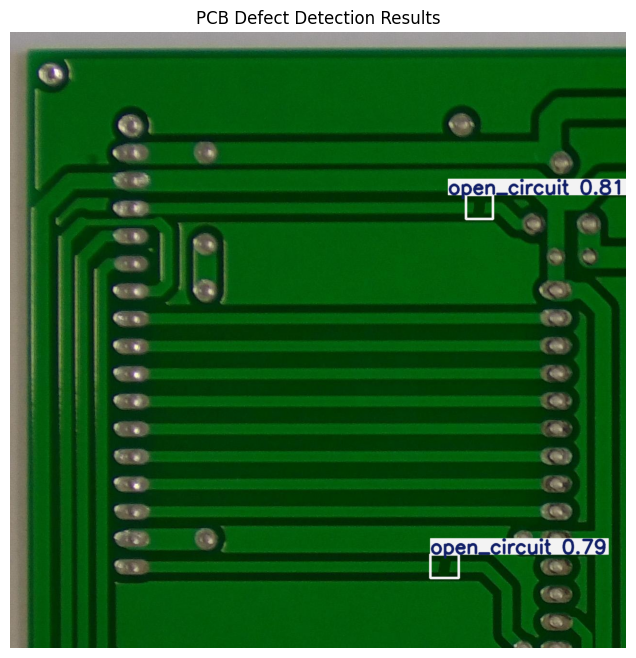

In [23]:
import cv2
import matplotlib.pyplot as plt

# Get annotated image
annotated_image = results[0].plot()

# Convert BGR to RGB
annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

# Display
plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.title("PCB Defect Detection Results")
plt.show()

In [24]:
result = results[0]

if len(result.boxes) > 0:

    print("Detected PCB Defects:\n")

    for box in result.boxes:

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        class_name = model.names[class_id]

        print(
            f"Defect: {class_name} | "
            f"Confidence: {confidence * 100:.2f}%"
        )

else:
    print("No PCB defects detected.")

Detected PCB Defects:

Defect: open_circuit | Confidence: 80.88%
Defect: open_circuit | Confidence: 79.01%


In [25]:
from google.colab import files
import os

output_path = "/content/pcb_predictions/external_image/" + os.path.basename(image_path)

if os.path.exists(output_path):
    files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>